## Vantara Customer Intelligence Platform

### 1. Exploratory Data Analysis (EDA)

This notebook analyzes the Online Retail II dataset to understand its structure, data quality, missing values, transaction patterns, and customer purchasing behavior.

It uses a limited data sample to generate initial insights without modifying the original dataset.

In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

BASE_DIR = Path.cwd()
if not (BASE_DIR / "data").exists():
    BASE_DIR = BASE_DIR.parent

RAW_FILE = BASE_DIR / "data" / "interim" / "combined_retail_data.csv"
CLEAN_FILE = BASE_DIR / "data" / "interim" / "cleaned_retail_data.csv"
EDA_DIR = BASE_DIR / "data" / "processed" / "eda"

print("Project:", BASE_DIR)
print("Combined data exists:", RAW_FILE.exists())
print("Cleaned data exists:", CLEAN_FILE.exists())
print("EDA output folder exists:", EDA_DIR.exists())

Project: c:\Users\RITUL\OneDrive\Desktop\AI Projects\customer-behavior-prediction
Combined data exists: True
Cleaned data exists: True
EDA output folder exists: True


In [3]:
# Read a sample only; do not load the entire large CSV.
data_file = CLEAN_FILE if CLEAN_FILE.exists() else RAW_FILE

if data_file.exists():
    df = pd.read_csv(data_file, nrows=100_000, low_memory=False)
    print("File:", data_file.name)
    print("Sample shape:", df.shape)
    display(df.head())
else:
    print("No interim CSV found. Check the data/interim folder.")

File: cleaned_retail_data.csv
Sample shape: (100000, 13)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer_ID,Country,IsCancellation,IsReturn,Quantity_Outlier,Price_Outlier,TotalAmount
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,False,False,False,False,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,False,False,False,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,False,False,False,False,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,False,False,True,False,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,False,False,False,False,30.0


In [4]:
if "df" in globals():
    print("Column names:")
    display(pd.DataFrame({"column": df.columns, "dtype": df.dtypes.astype(str).values}))
    print("Missing values in loaded sample:")
    display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
    print("Duplicate rows in loaded sample:", df.duplicated().sum())
    display(df.describe(include="all").T)

Column names:


,column,dtype
0,Invoice,object
1,StockCode,object
2,Description,object
3,Quantity,int64
4,InvoiceDate,object
5,Price,float64
6,Customer_ID,float64
7,Country,object
8,IsCancellation,bool
9,IsReturn,bool


Missing values in loaded sample:


,missing_count
Invoice,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
Price,0
Customer_ID,0
Country,0
IsCancellation,0
IsReturn,0


Duplicate rows in loaded sample: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Invoice,100000,5907,500356,251,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,100000,3355,85123A,938,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,100000,3320,WHITE HANGING HEART T-LIGHT HOLDER,938,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,100000.0,NaN,NaN,NaN,15.0833,153.936901,-2504.0,2.0,5.0,12.0,19152.0
InvoiceDate,100000,5475,2010-03-07 15:34:00,251,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,100000.0,NaN,NaN,NaN,4.348112,88.31461,0.001,1.25,2.1,3.75,10953.5
Customer_ID,100000.0,NaN,NaN,NaN,15324.0373,1680.195408,12346.0,13931.0,15222.0,16798.0,18287.0
Country,100000,27,United Kingdom,91399,NaN,NaN,NaN,NaN,NaN,NaN,NaN
IsCancellation,100000,2,False,97217,NaN,NaN,NaN,NaN,NaN,NaN,NaN
IsReturn,100000,2,False,97217,NaN,NaN,NaN,NaN,NaN,NaN,NaN


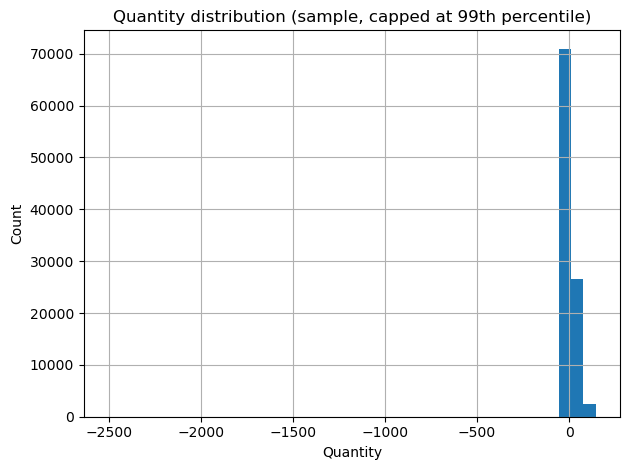

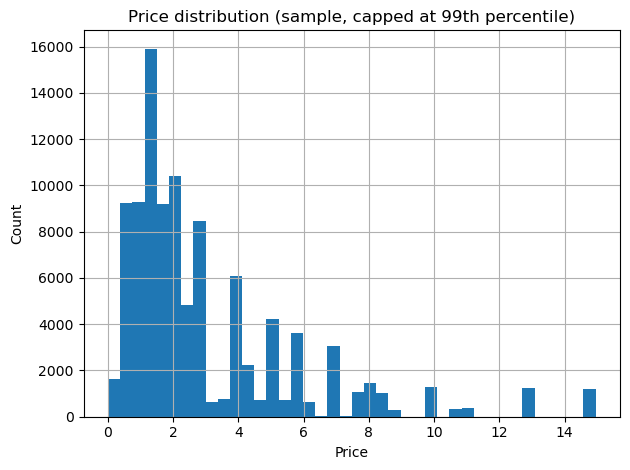

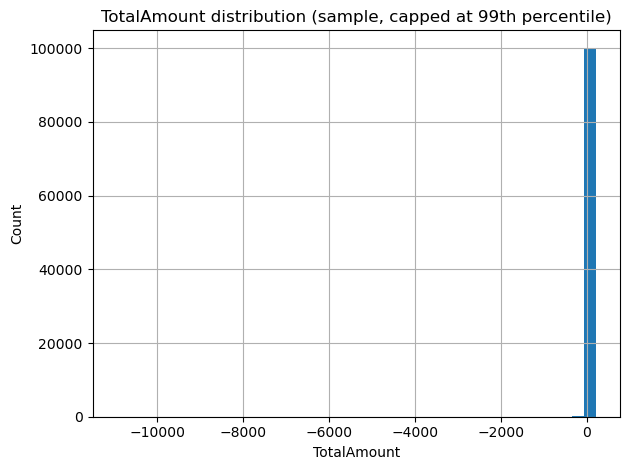

In [5]:
# Sample distributions, where the relevant columns exist.
if "df" in globals():
    for col in ["Quantity", "Price", "TotalAmount"]:
        if col in df.columns:
            values = pd.to_numeric(df[col], errors="coerce").dropna()
            if not values.empty:
                values.clip(
                    upper=values.quantile(0.99)
                ).hist(bins=40)
                plt.title(f"{col} distribution (sample, capped at 99th percentile)")
                plt.xlabel(col)
                plt.ylabel("Count")
                plt.tight_layout()
                plt.show()

In [6]:
# Review existing EDA outputs without regenerating them.
if EDA_DIR.exists():
    files = sorted(p.name for p in EDA_DIR.iterdir() if p.is_file())
    display(pd.DataFrame({"existing_eda_output": files}))
    for name in ["basic_summary.csv", "monthly_analysis.csv",
                 "churn_vs_features.csv", "country_analysis.csv"]:
        p = EDA_DIR / name
        if p.exists():
            print(f"Preview: {name}")
            display(pd.read_csv(p, nrows=10))
else:
    print("Existing EDA output folder not found.")

,existing_eda_output
0,average_basket_size_distribution.png
1,average_order_value_distribution.png
2,basic_summary.csv
3,churn_distribution.png
4,churn_vs_features.csv
5,clv_distribution.png
6,clv_vs_churn.png
7,correlation_heatmap.png
8,correlation_matrix.csv
9,country_analysis.csv


Preview: basic_summary.csv


,Unnamed: 0,Recency,Frequency,Monetary,Average_Order_Value,Average_Basket_Size,CLV,Return_Rate,Engagement_Score
0,count,5281.000000,5281.000000,5281.000000,5281.000000,5281.000000,5281.000000,5281.000000,5281.000000
1,mean,207.282901,5.745692,2637.863286,39.054413,241.689115,139.234620,0.027788,0.019145
2,std,175.007174,11.464582,12225.544955,277.646590,1400.038545,740.029644,0.070838,0.041394
3,min,0.000000,1.000000,2.900000,1.450000,1.000000,0.170260,0.000000,0.001607
4,25%,49.000000,1.000000,318.240000,11.523906,87.000000,4.203264,0.000000,0.003283
5,50%,164.000000,3.000000,783.580000,17.355875,148.000000,10.560404,0.000000,0.006810
6,75%,326.000000,6.000000,2078.540000,24.341287,251.000000,135.400000,0.026042,0.016555
7,max,648.000000,309.000000,456780.490000,13305.500000,87167.000000,39916.500000,0.755102,0.637803


Preview: monthly_analysis.csv


,Month,Orders,Customers,Revenue
0,1,2532,1300,1004168.412
1,2,2534,1359,923130.496
2,3,3526,1764,1211995.521
3,4,2999,1594,983230.503
4,5,3617,1754,1204885.060
5,6,3540,1776,1175647.070
6,7,3306,1633,1133997.651
7,8,3090,1587,1200337.550
8,9,4118,2047,1707876.283
9,10,4849,2476,1934827.120


Preview: churn_vs_features.csv


,Churn,Recency,Frequency,Monetary,Average_Order_Value,CLV,Return_Rate,Engagement_Score
0,0,120.043194,9.254799,4598.242739,28.773073,77.535312,0.025635,0.031876
1,1,274.179324,3.054868,1134.621498,46.938265,186.546368,0.029439,0.009382


Preview: country_analysis.csv


,Country,Customers,Orders,Revenue
0,United Kingdom,5407,40500,1.348251e+07
1,EIRE,5,727,5.735098e+05
2,Netherlands,23,249,5.483307e+05
3,Germany,107,1095,4.119592e+05
4,France,95,738,3.200463e+05
5,Australia,15,117,1.664444e+05
6,Switzerland,22,120,9.877941e+04
7,Spain,41,188,9.101344e+04
8,Sweden,19,128,8.742152e+04
9,Denmark,12,53,6.445959e+04
